In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm

In [28]:
from pygraphon.graphons.GraphonFunction import Graphon
from pygraphon.plots.plots_graphon import plot_sample

(<Figure size 432x360 with 2 Axes>, <AxesSubplot:>)

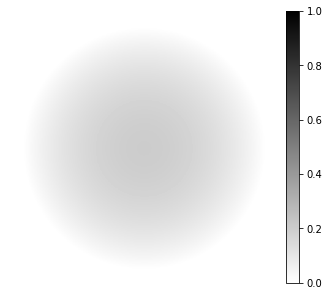

In [64]:
graphon = Graphon(lambda x, y:  0.2 - ((x-0.5)**2 + (y-0.5)**2) , scaled=True)

fig, ax = plt.subplots(1,1,figsize=(6, 5))
plot_sample(graphon, fig = fig, ax = ax, colorbar= True)

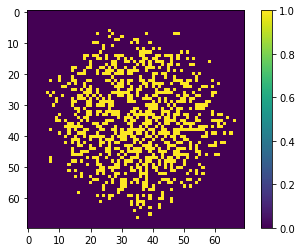

In [73]:
graph = graphon.draw(rho = 0.1, n = 70, exchangeable= False)
plt.imshow(graph)
plt.colorbar()

In [74]:
from pygraphon.estimators.HistogramEstimator import HistogramEstimator

In [75]:
estimator = HistogramEstimator(bandwithHist=None)
graphon_estimated = estimator.estimate(adjacency_matrix = graph)

(<Figure size 432x360 with 2 Axes>, <AxesSubplot:>)

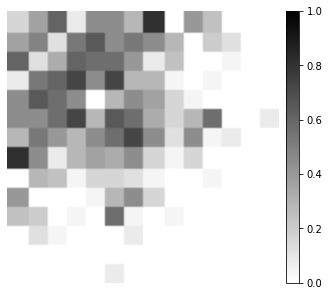

In [76]:
fig, ax = plt.subplots(1,1,figsize=(6, 5))
plot_sample(graphon_estimated, fig = fig, ax = ax, colorbar= True)

In [91]:

graphon_matrix = np.array([[0.8,0.1,0.1],[0.1,0.8,0.1],[0.1,0.1,0.8]])
graphon = StepGraphon(graphon_matrix,1/3)

In [92]:
print(graphon.integral(graphon_matrix), graphon.integral())

0.33333333333333337 1.0


In [93]:
graphon.graphon

array([[2.4, 0.3, 0.3],
       [0.3, 2.4, 0.3],
       [0.3, 0.3, 2.4]])

In [94]:
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt

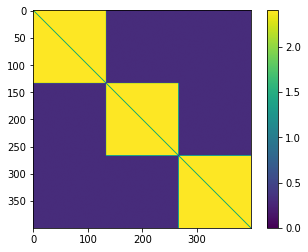

In [95]:
plt.imshow(graphon._get_edge_probabilities(400,False,True))
plt.colorbar()
plt.show()

In [98]:
A = graphon.draw(rho = 0.3,n = 90, exchangeable=False)

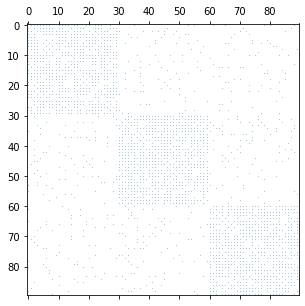

In [99]:
fig, ax = spy(A)
plt.show()

In [100]:
edge_density(A)

0.29213483146067415

In [101]:
from pygraphon.estimators.HistogramEstimator import HistogramEstimator
from pygraphon.estimators.MomentEstimator import MomentEstimator, SimpleMomentEstimator

In [102]:
hist = HistogramEstimator()
hist_epprox = hist.estimate(adjacency_matrix= A, bandwidthHist= None)

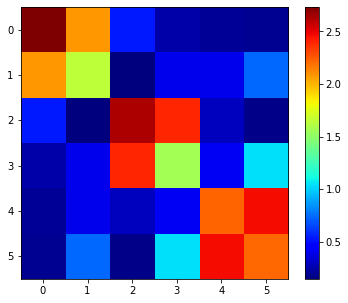

In [103]:
from pygraphon.plots.plots_graphon import plot
plot(hist_epprox)
plt.show()

In [47]:
from pygraphon.subgraph_isomorphism.CycleCount import CycleCount
counter = CycleCount(L = 9)

In [49]:
momentestimator = SimpleMomentEstimator(3)
mome_simple_approx = momentestimator.estimate(adjacency_matrix= A)

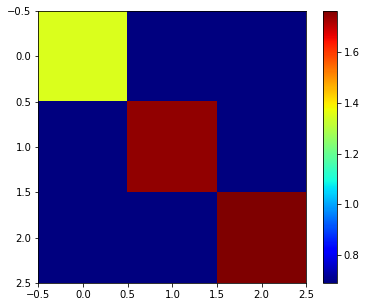

In [50]:
plot(mome_simple_approx)
plt.show()

In [51]:
mome_simple_approx.graphon

array([[1.3504888 , 0.69059531, 0.69059531],
       [0.69059531, 1.7444674 , 0.69059531],
       [0.69059531, 0.69059531, 1.76147196]])

In [52]:
mome_simple_approx.integral()

1.0